## Import & Path

In [4]:
# ============================================================
# CELL 1 — IMPORT LIBRARY & KONFIGURASI PATH
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

from scipy.stats import skew, kurtosis, jarque_bera, norm

mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['figure.dpi'] = 200
plt.rcParams['figure.dpi'] = 200

ROOT_DIR = Path('../../')

RAW_DIR = ROOT_DIR / '03_dataset' / 'raw'
PROCESSED_DIR = ROOT_DIR / '03_dataset' / 'processed'
OUTPUT_DIR = ROOT_DIR / '06_dokumen_tesis'

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

colors = {
    'ADRO': '#1f77b4',
    'ADMR': '#2ca02c',
    'ITMG': '#ff7f0e',
    'PTBA': '#d62728',
    'MEDC': '#9467bd',
    'AKRA': '#8c564b',
    'PGAS': '#e377c2'
}

## Load data & hitung log return

In [5]:
# ============================================================
# CELL 2 — LOAD DATA & HITUNG LOG RETURN (FIXED)
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ===== PATH FIX =====
RAW_DIR = Path(r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw")

INPUT_FILE = RAW_DIR / "harga_saham_raw.csv"

# ===== CEK FILE =====
assert INPUT_FILE.exists(), f"File tidak ditemukan:\n{INPUT_FILE}"

# ===== LOAD DATA =====
df = pd.read_csv(INPUT_FILE, encoding='utf-8-sig')

# ===== CLEAN COLUMN =====
df.columns = df.columns.str.strip()

# ===== CEK KOLOM WAJIB =====
required_cols = ['Date', 'Kode_Emiten', 'Adj Close']
missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    # Normalisasi nama kolom agar sesuai dengan code notebook
    rename_map = {}
    if 'Adj_Close' in df.columns and 'Adj Close' not in df.columns:
        rename_map['Adj_Close'] = 'Adj Close'
    if 'Emiten' in df.columns and 'Kode_Emiten' not in df.columns:
        rename_map['Emiten'] = 'Kode_Emiten'

    if rename_map:
        df = df.rename(columns=rename_map)

    # Cek ulang setelah rename
    missing_cols = [c for c in required_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Kolom hilang di dataset: {missing_cols}\nKolom tersedia: {df.columns.tolist()}")

# ===== FORMAT DATE =====
df['Date'] = pd.to_datetime(df['Date'])

# ===== SORT =====
df = df.sort_values(['Kode_Emiten', 'Date']).reset_index(drop=True)

# ===== LOG RETURN =====
price_col = 'Adj Close'

df['Log_Return'] = (
    df.groupby('Kode_Emiten')[price_col]
      .transform(lambda x: np.log(x / x.shift(1)))
)

display(df.head())

,Date,Open,High,Low,Close,Adj Close,Volume,Kode_Emiten,Log_Return
0,2022-01-03,135.0,135.0,135.0,135.0,125.224686,34289600,ADMR,NaN
1,2022-01-04,182.0,182.0,182.0,182.0,168.821442,22170900,ADMR,0.298732
2,2022-01-05,220.0,244.0,220.0,244.0,226.332031,43203600,ADMR,0.293161
3,2022-01-06,304.0,304.0,304.0,304.0,281.987457,52097500,ADMR,0.219860
4,2022-01-07,380.0,380.0,380.0,380.0,352.484314,19248600,ADMR,0.223144


## Statistik deskriptif log return

In [6]:
# ============================================================
# CELL 3 — STATISTIK DESKRIPTIF LOG RETURN
# ============================================================

summary = []

for kode in sorted(df['Kode_Emiten'].unique()):
    data = df[df['Kode_Emiten']==kode]['Log_Return'].dropna()

    summary.append({
        'Kode_Emiten': kode,
        'Mean': data.mean(),
        'Std': data.std(),
        'Min': data.min(),
        'Max': data.max(),
        'Skewness': skew(data),
        'Kurtosis': kurtosis(data)
    })

desc = pd.DataFrame(summary).round(6)
display(desc)

desc.to_csv(
    OUTPUT_DIR / 'Tabel_4_6_statistik_log_return.csv',
    index=False,
    encoding='utf-8-sig'
)

,Kode_Emiten,Mean,Std,Min,Max,Skewness,Kurtosis
0,ADMR,0.002300,0.041295,-0.130362,0.298732,1.821911,9.153596
1,ADRO,0.001296,0.027255,-0.282863,0.177196,-0.283687,13.797934
2,AKRA,0.000662,0.025191,-0.121214,0.200671,0.444616,4.899983
3,ITMG,0.000822,0.021110,-0.072351,0.148909,0.525168,4.945173
4,MEDC,0.000910,0.031406,-0.160623,0.186984,0.439512,3.236950
5,PGAS,0.000526,0.020589,-0.145050,0.107631,-0.068958,4.219695
6,PTBA,0.000615,0.020953,-0.161586,0.189605,0.504134,10.522905


## Time series log return

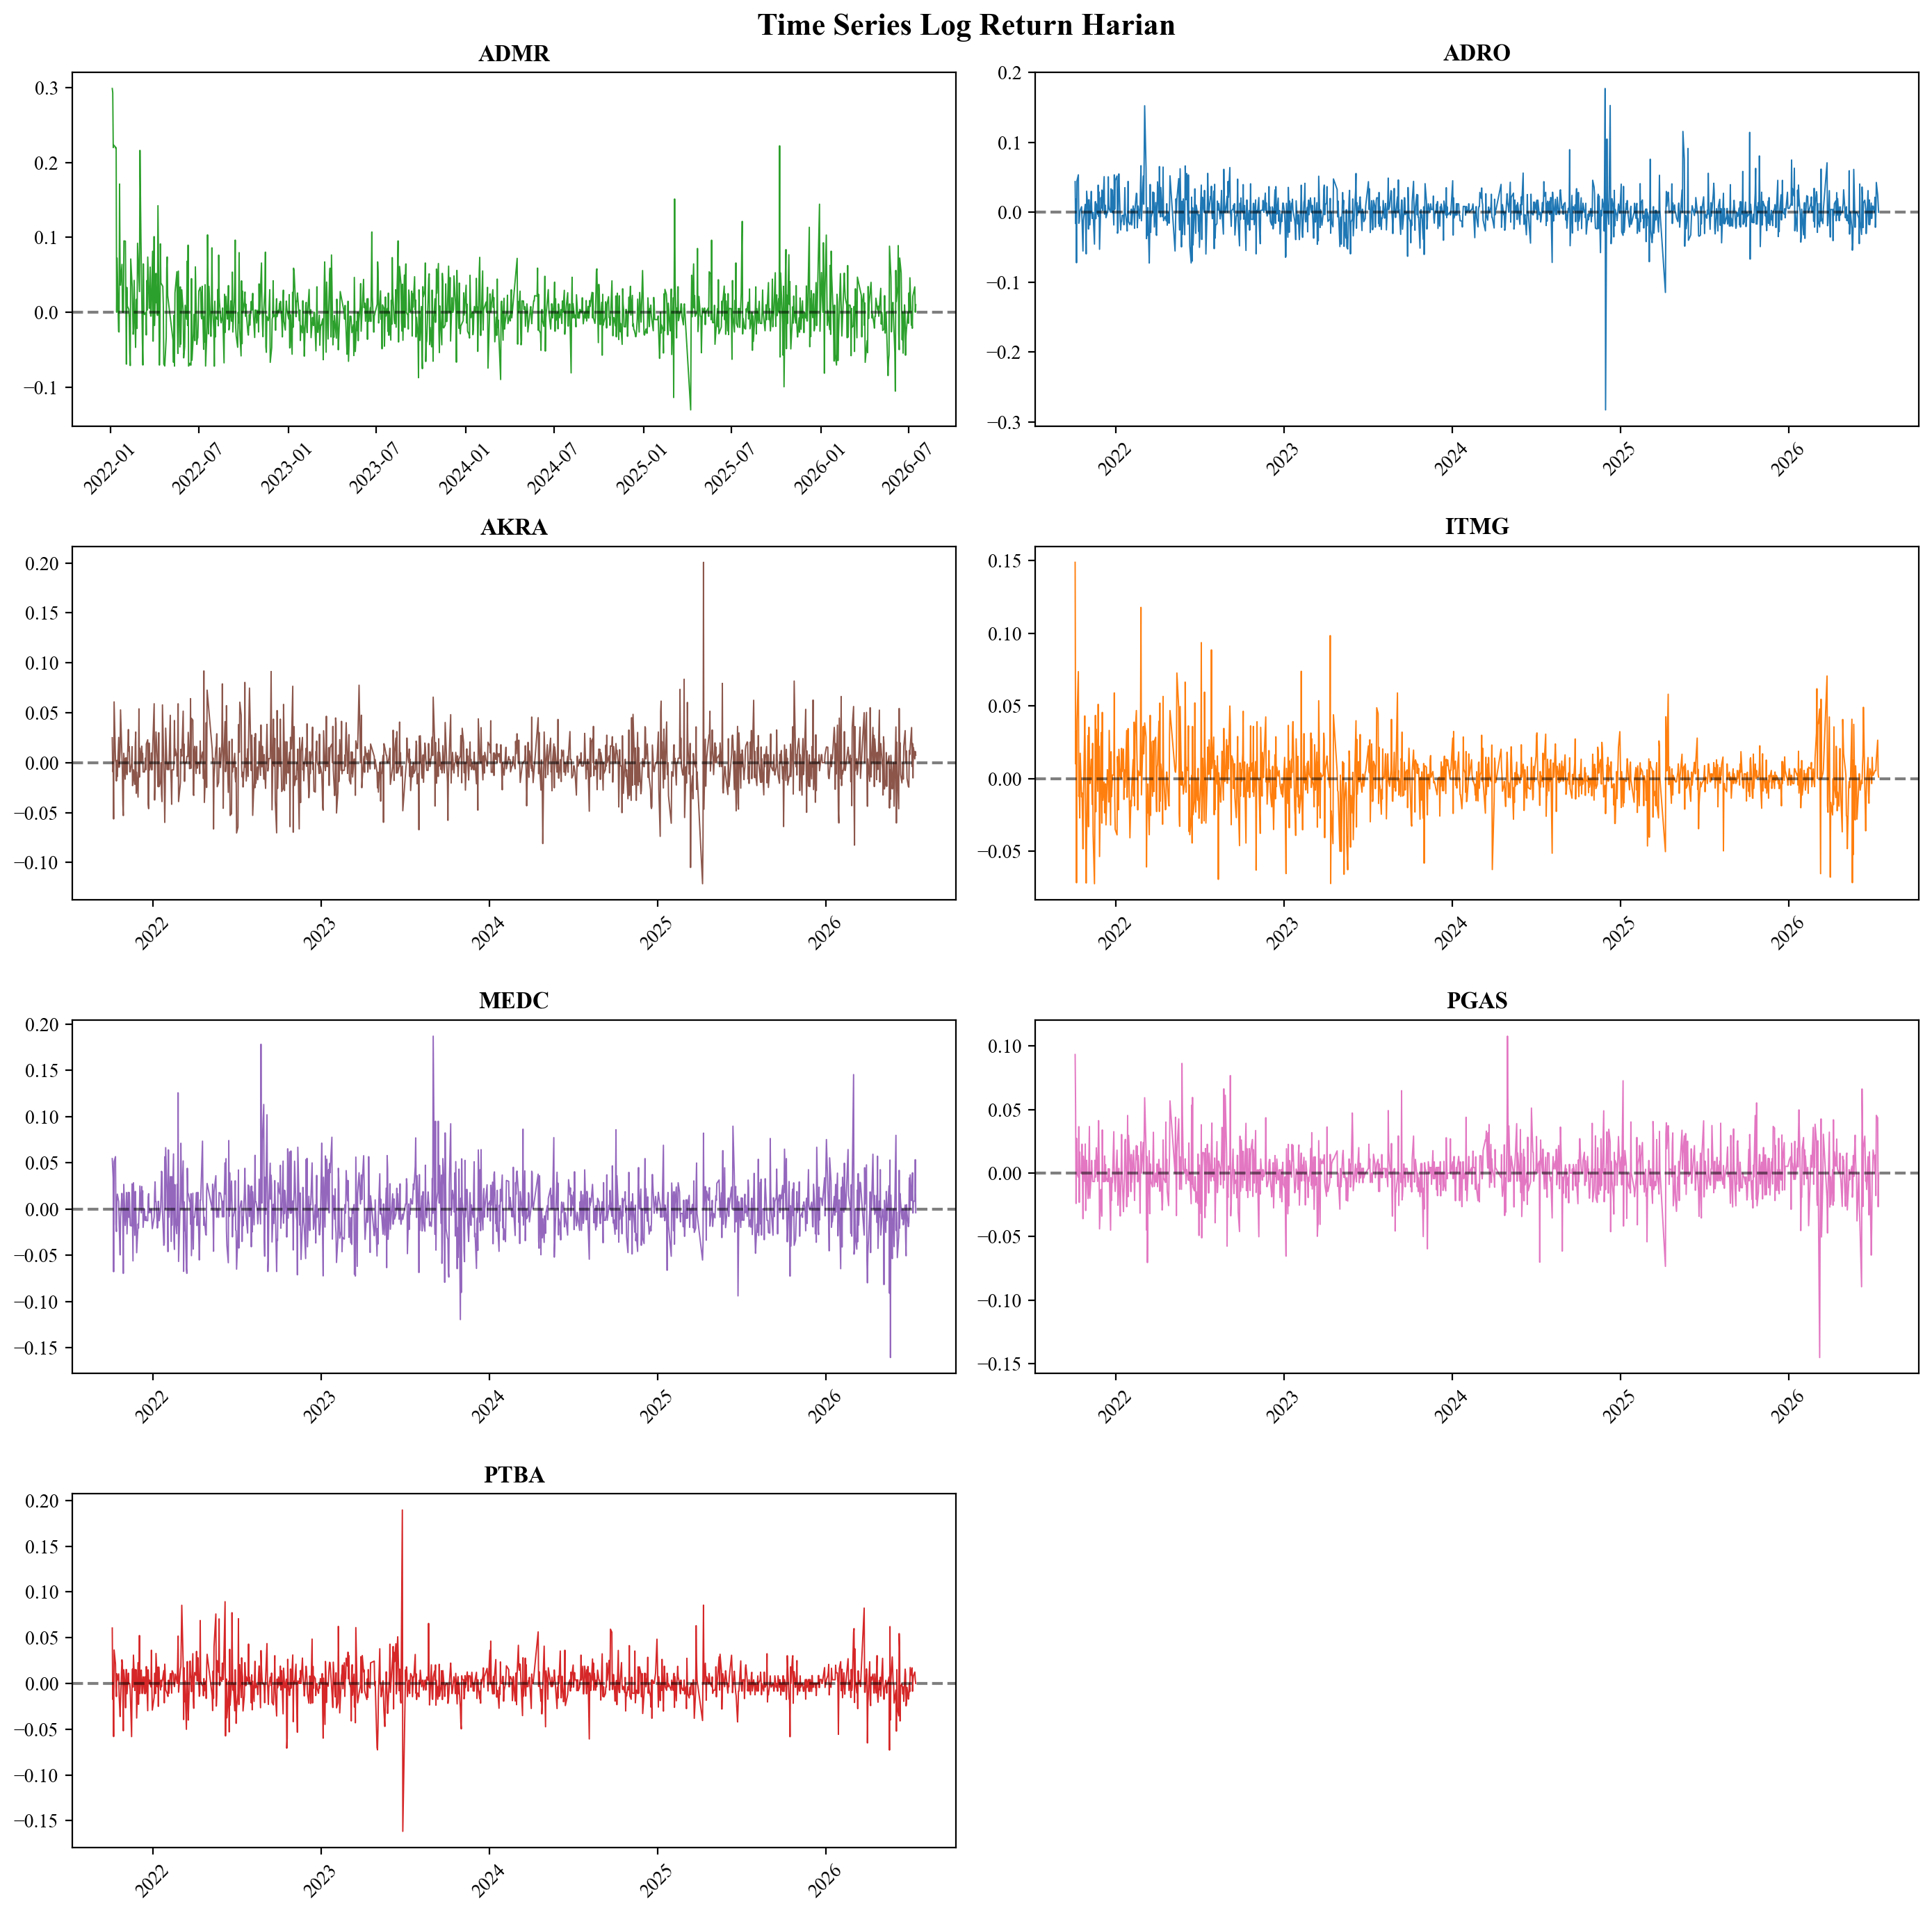

In [7]:
# ============================================================
# CELL 4 — TIME SERIES LOG RETURN
# ============================================================

emitens = sorted(df['Kode_Emiten'].unique())

fig, axes = plt.subplots(4, 2, figsize=(14,14))
axes = axes.flatten()

for i, kode in enumerate(emitens):
    ax = axes[i]
    sub = df[df['Kode_Emiten']==kode]

    ax.plot(
        sub['Date'],
        sub['Log_Return'],
        color=colors[kode],
        linewidth=0.7
    )

    ax.axhline(0, linestyle='--', color='black', alpha=0.5)
    ax.set_title(kode, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)

for j in range(len(emitens), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Time Series Log Return Harian",
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Histogram log return

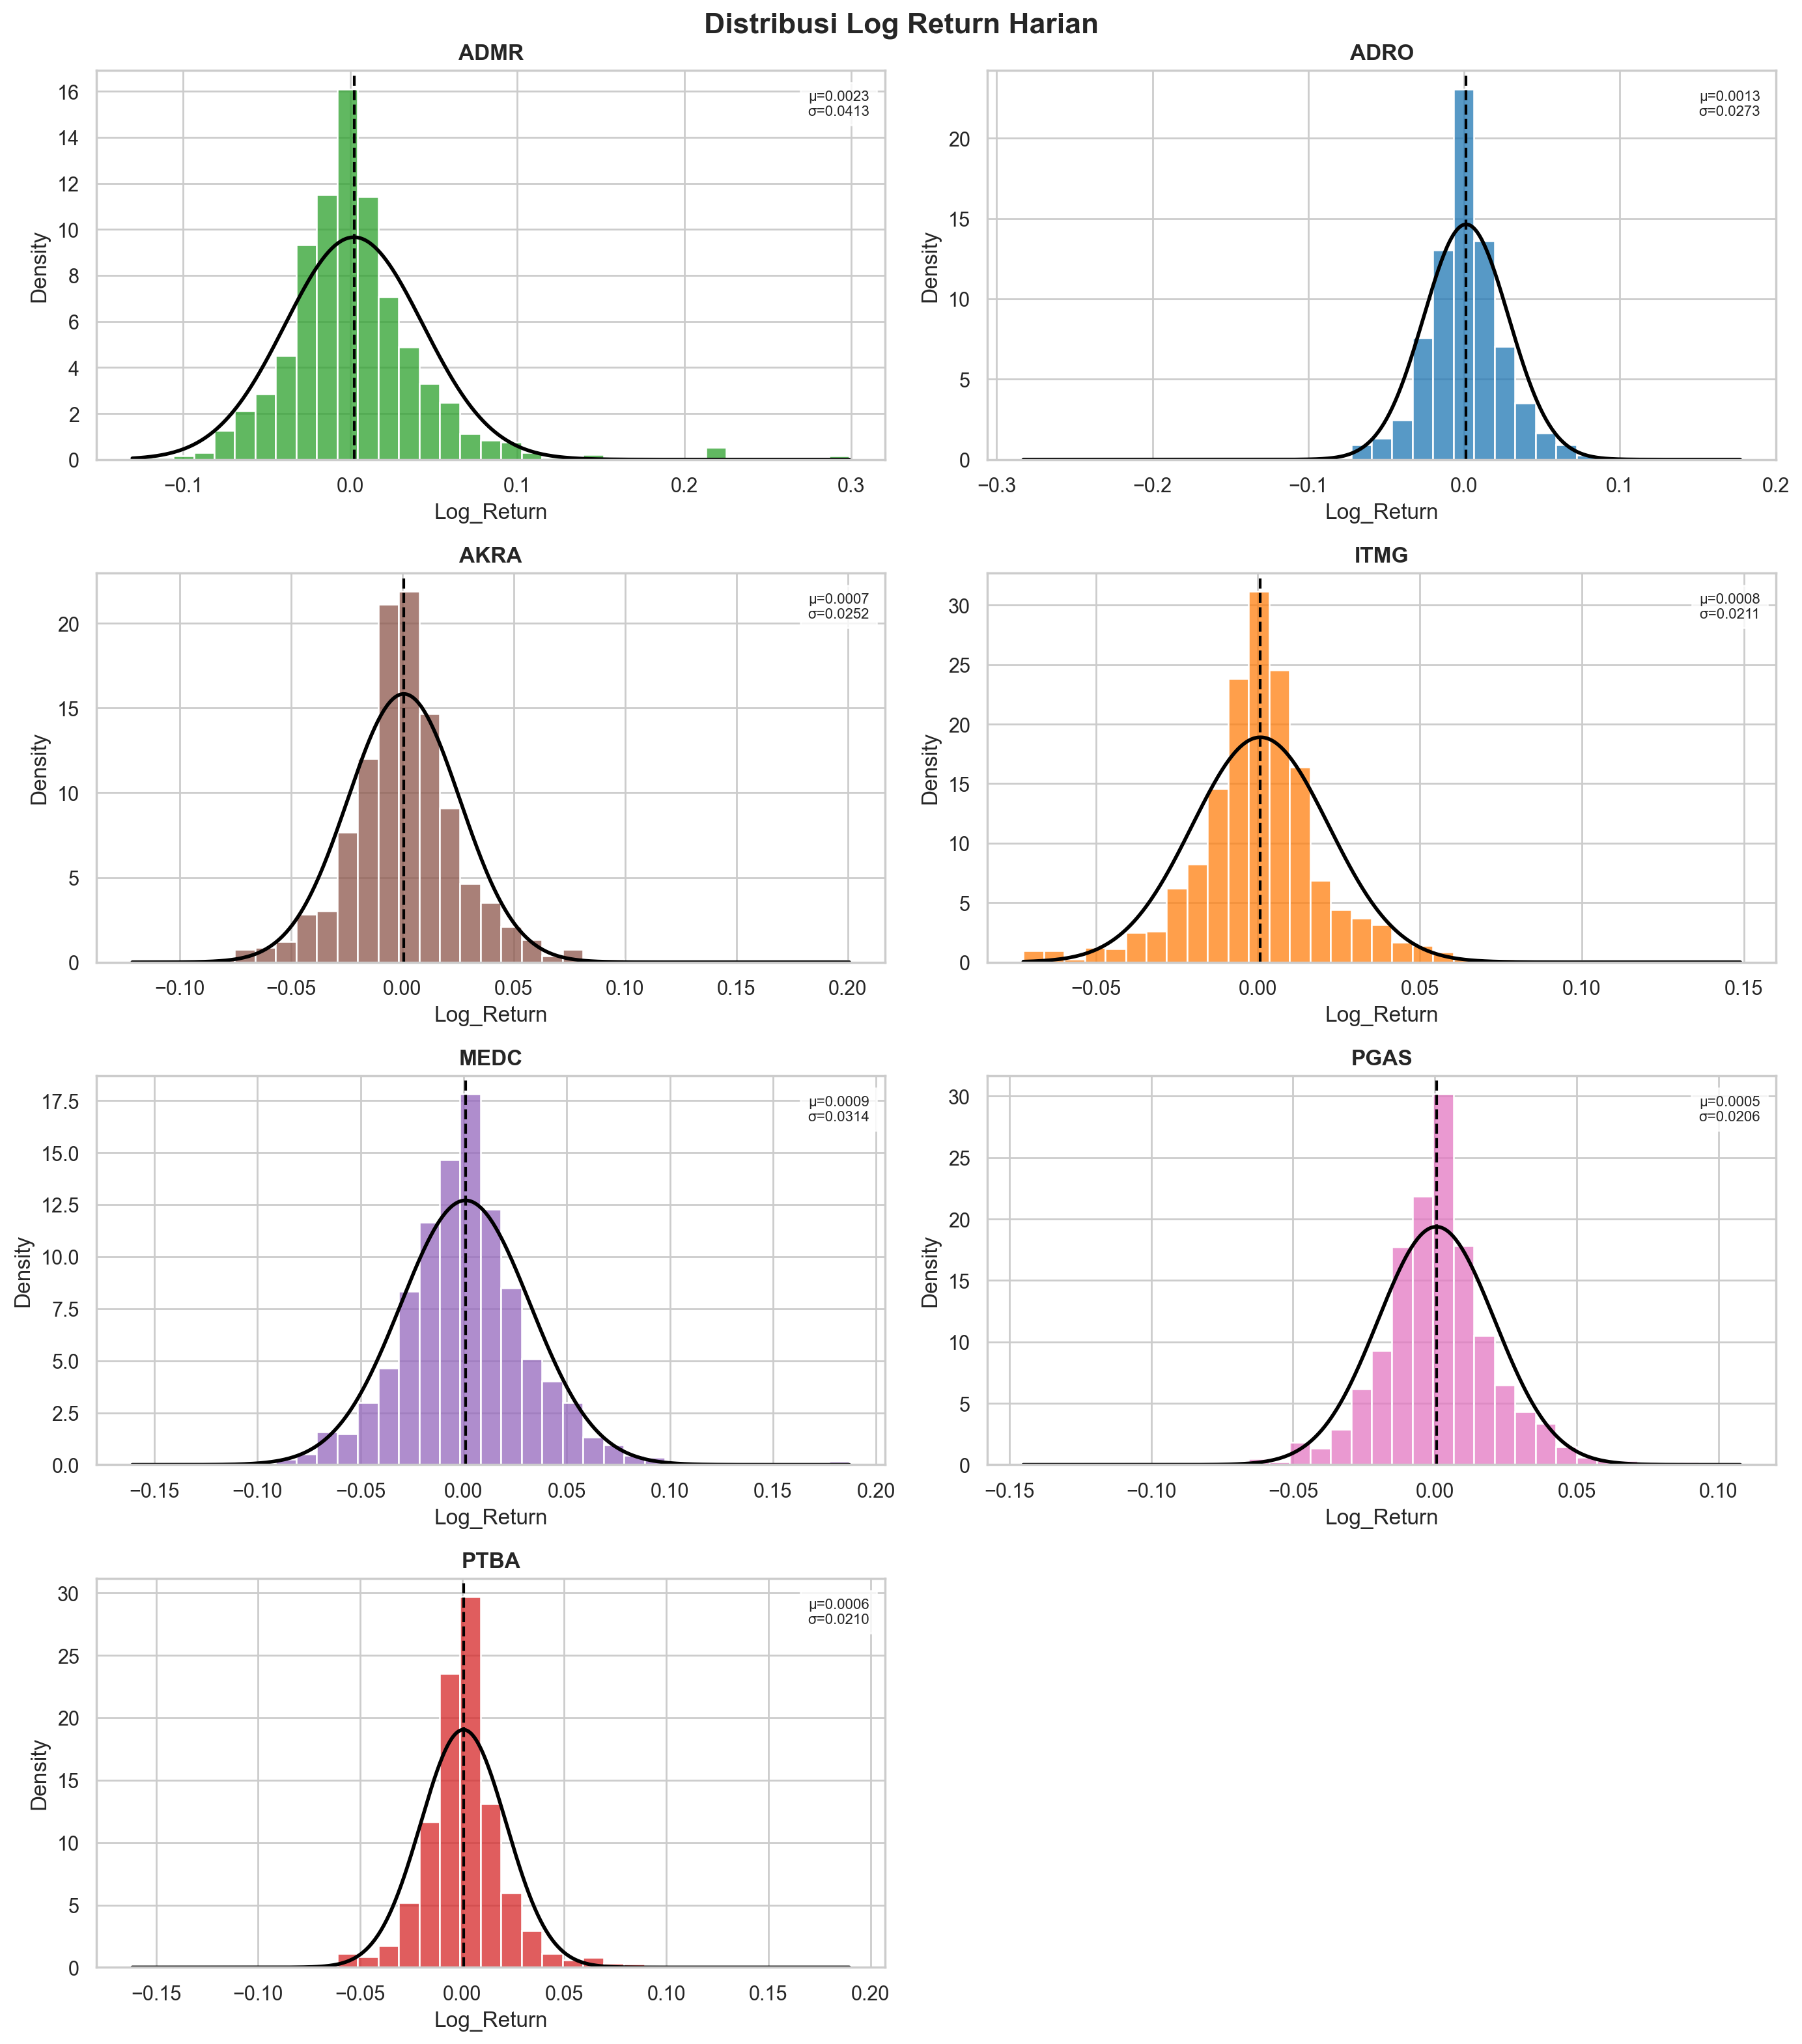

In [8]:
# ============================================================
# CELL 5 — HISTOGRAM LOG RETURN
# ============================================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(4, 2, figsize=(14,16))
axes = axes.flatten()

for i, kode in enumerate(emitens):
    ax = axes[i]

    data = df[df['Kode_Emiten']==kode]['Log_Return'].dropna()

    mu = data.mean()
    sigma = data.std()

    sns.histplot(
        data,
        bins=35,
        stat='density',
        kde=False,
        color=colors[kode],
        edgecolor='white',
        alpha=0.75,
        ax=ax
    )

    x = np.linspace(data.min(), data.max(), 500)
    y = norm.pdf(x, mu, sigma)

    ax.plot(x, y, linewidth=2, color='black')
    ax.axvline(mu, linestyle='--', color='black')

    ax.set_title(kode, fontweight='bold')

    ax.text(
        0.98, 0.95,
        f'μ={mu:.4f}\nσ={sigma:.4f}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=8,
        bbox=dict(facecolor='white', alpha=0.8)
    )

for j in range(len(emitens), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Distribusi Log Return Harian",
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Jarque-Bera Test

In [9]:
# ============================================================
# CELL 6 — UJI NORMALITAS
# ============================================================

jb_results = []

for kode in emitens:
    data = df[df['Kode_Emiten']==kode]['Log_Return'].dropna()

    jb_stat, pval = jarque_bera(data)

    jb_results.append({
        'Kode_Emiten': kode,
        'JB Statistic': jb_stat,
        'p-value': pval,
        'Kesimpulan':
            'Normal' if pval > 0.05 else 'Tidak Normal'
    })

jb = pd.DataFrame(jb_results)
display(jb)

jb.to_csv(
    OUTPUT_DIR / 'Tabel_Jarque_Bera.csv',
    index=False,
    encoding='utf-8-sig'
)

# ============================================================
# INTERPRETASI HASIL JARQUE-BERA
# ============================================================

jumlah_normal = (jb['Kesimpulan'] == 'Normal').sum()
jumlah_tidak_normal = (jb['Kesimpulan'] == 'Tidak Normal').sum()

print("="*70)
print("INTERPRETASI UJI NORMALITAS JARQUE-BERA")
print("="*70)

print(
    f"Dari {len(jb)} emiten yang dianalisis, "
    f"sebanyak {jumlah_normal} emiten berdistribusi normal "
    f"dan {jumlah_tidak_normal} emiten tidak berdistribusi normal."
)

print()
print(
    "Hasil ini menunjukkan bahwa distribusi log return saham "
    "sektor energi LQ45 cenderung tidak mengikuti distribusi normal "
    "serta memiliki karakteristik non-linear dan heavy tails."
)

print()
print(
    "Karakteristik tersebut mendukung penggunaan model machine learning "
    "dan deep learning dalam penelitian ini."
)

print()
print("Alasan pemilihan model:")
print("- XGBoost cocok untuk menangkap pola non-linear dan interaksi antar fitur.")
print("- LSTM cocok untuk menangkap dependensi temporal dan volatility clustering.")


,Kode_Emiten,JB Statistic,p-value,Kesimpulan
0,ADMR,4384.136230,0.000000e+00,Tidak Normal
1,ADRO,9122.050284,0.000000e+00,Tidak Normal
2,AKRA,1186.294011,2.509162e-258,Tidak Normal
3,ITMG,1222.521371,3.410808e-266,Tidak Normal
4,MEDC,538.150246,1.387263e-117,Tidak Normal
5,PGAS,852.621704,7.170499e-186,Tidak Normal
6,PTBA,5345.285279,0.000000e+00,Tidak Normal


INTERPRETASI UJI NORMALITAS JARQUE-BERA
Dari 7 emiten yang dianalisis, sebanyak 0 emiten berdistribusi normal dan 7 emiten tidak berdistribusi normal.

Hasil ini menunjukkan bahwa distribusi log return saham sektor energi LQ45 cenderung tidak mengikuti distribusi normal serta memiliki karakteristik non-linear dan heavy tails.

Karakteristik tersebut mendukung penggunaan model machine learning dan deep learning dalam penelitian ini.

Alasan pemilihan model:
- XGBoost cocok untuk menangkap pola non-linear dan interaksi antar fitur.
- LSTM cocok untuk menangkap dependensi temporal dan volatility clustering.


## Save dataset

In [10]:
# ============================================================
# CELL 7 — SAVE LOG RETURN
# ============================================================

df.to_csv(
    PROCESSED_DIR / 'log_return.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Saved:", PROCESSED_DIR / 'log_return.csv')

Saved: ..\..\03_dataset\processed\log_return.csv
